# DMV Practical 7 – Apple Stock Time Series and ARIMA Forecasting

**Aim:** Analyze Apple stock data, calculate moving averages, summarize monthly patterns, inspect correlations, and forecast closing prices using ARIMA.

Uses the Plotly Apple finance CSV shown in the PDF. The notebook installs statsmodels in the ARIMA cell.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv"
df = pd.read_csv(url)
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
df.info()
display(df.describe())
print("Missing values:\n", df.isnull().sum())

Dataset loaded successfully!
Shape: (506, 11)
Columns: ['Date', 'AAPL.Open', 'AAPL.High', 'AAPL.Low', 'AAPL.Close', 'AAPL.Volume', 'AAPL.Adjusted', 'dn', 'mavg', 'up', 'direction']


,Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction
0,2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.741052,117.927667,129.114281,Increasing
1,2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.940333,130.038244,Increasing
2,2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.894245,119.889167,130.884089,Decreasing
3,2015-02-20,128.619995,129.500000,128.050003,129.500000,48948400,124.510914,109.785449,120.763500,131.741551,Increasing
4,2015-02-23,130.020004,133.000000,129.660004,133.000000,70974100,127.876074,110.372516,121.720167,133.067817,Increasing


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           506 non-null    object 
 1   AAPL.Open      506 non-null    float64
 2   AAPL.High      506 non-null    float64
 3   AAPL.Low       506 non-null    float64
 4   AAPL.Close     506 non-null    float64
 5   AAPL.Volume    506 non-null    int64  
 6   AAPL.Adjusted  506 non-null    float64
 7   dn             506 non-null    float64
 8   mavg           506 non-null    float64
 9   up             506 non-null    float64
 10  direction      506 non-null    object 
dtypes: float64(8), int64(1), object(2)
memory usage: 43.6+ KB


,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up
count,506.000000,506.000000,506.000000,506.000000,5.060000e+02,506.000000,506.000000,506.000000,506.000000
mean,112.935000,113.919447,111.942016,112.958340,4.317842e+07,110.459312,107.311385,112.739865,118.168345
std,11.287490,11.251892,11.263687,11.244744,1.985253e+07,10.537529,11.095804,10.595315,10.670752
min,90.000000,91.669998,89.470001,90.339996,1.147590e+07,89.008370,85.508858,94.047166,97.572721
25%,105.482500,106.349999,104.657501,105.672499,2.974240e+07,103.484803,97.011245,104.954875,111.052267
50%,112.889999,114.145001,111.800003,113.025002,3.747460e+07,110.821123,107.351628,112.799750,118.472542
75%,122.267498,123.497500,121.599998,122.179998,5.076395e+07,119.255457,114.812152,121.889416,128.515793
max,135.669998,136.270004,134.839996,135.509995,1.622063e+08,135.509995,127.289258,129.845000,138.805366


Missing values:
 Date             0
AAPL.Open        0
AAPL.High        0
AAPL.Low         0
AAPL.Close       0
AAPL.Volume      0
AAPL.Adjusted    0
dn               0
mavg             0
up               0
direction        0
dtype: int64


In [2]:
# Prepare dates and sort
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
display(df.head())

,Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction
0,2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.741052,117.927667,129.114281,Increasing
1,2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.940333,130.038244,Increasing
2,2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.894245,119.889167,130.884089,Decreasing
3,2015-02-20,128.619995,129.500000,128.050003,129.500000,48948400,124.510914,109.785449,120.763500,131.741551,Increasing
4,2015-02-23,130.020004,133.000000,129.660004,133.000000,70974100,127.876074,110.372516,121.720167,133.067817,Increasing


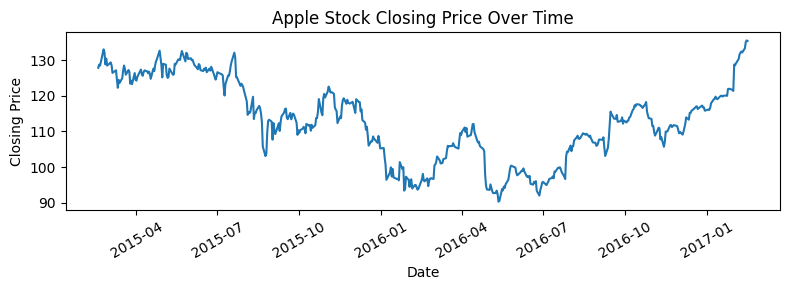

,Date,AAPL.Close,MA_20,MA_50
501,2017-02-10,132.119995,124.618499,118.954600
502,2017-02-13,133.289993,125.330998,119.409999
503,2017-02-14,135.020004,126.081998,119.920600
504,2017-02-15,135.509995,126.857998,120.432799
505,2017-02-16,135.350006,127.636499,120.957600


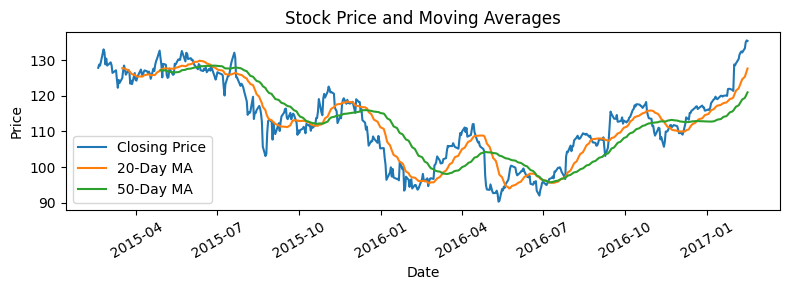

In [3]:
# Closing price over time
plt.figure(figsize=(8,3))
plt.plot(df["Date"], df["AAPL.Close"])
plt.xlabel("Date"); plt.ylabel("Closing Price")
plt.title("Apple Stock Closing Price Over Time")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# 20-day and 50-day moving averages
df["MA_20"] = df["AAPL.Close"].rolling(window=20).mean()
df["MA_50"] = df["AAPL.Close"].rolling(window=50).mean()
display(df[["Date","AAPL.Close","MA_20","MA_50"]].tail())

plt.figure(figsize=(8,3))
plt.plot(df["Date"], df["AAPL.Close"], label="Closing Price")
plt.plot(df["Date"], df["MA_20"], label="20-Day MA")
plt.plot(df["Date"], df["MA_50"], label="50-Day MA")
plt.xlabel("Date"); plt.ylabel("Price")
plt.title("Stock Price and Moving Averages")
plt.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

Average Closing Price by Month:


Month
1     109.270512
2     113.809755
3     115.119091
4     117.015238
5     111.456097
6     112.214545
7     112.583571
8     110.399773
9     111.827381
10    114.506279
11    114.060731
12    113.000930
Name: AAPL.Close, dtype: float64

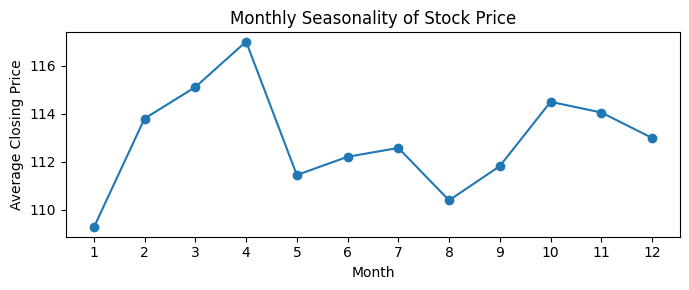

Month
1     4.702492e+07
2     4.374527e+07
3     4.283390e+07
4     4.448885e+07
5     4.523098e+07
6     3.767201e+07
7     4.150683e+07
8     5.082061e+07
9     5.177531e+07
10    4.184273e+07
11    3.590234e+07
12    3.558840e+07
Name: AAPL.Volume, dtype: float64

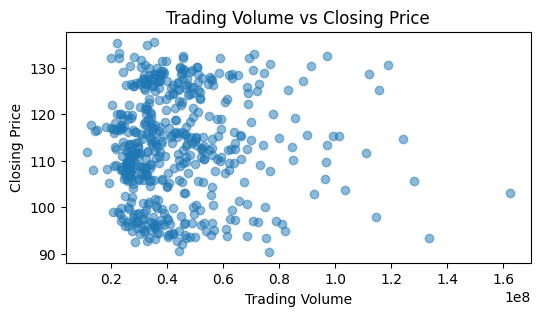

In [4]:
# Monthly analysis and volume
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
monthly_avg = df.groupby("Month")["AAPL.Close"].mean()
print("Average Closing Price by Month:")
display(monthly_avg)

monthly_avg.plot(marker="o", figsize=(7,3), title="Monthly Seasonality of Stock Price")
plt.xlabel("Month"); plt.ylabel("Average Closing Price"); plt.xticks(range(1,13))
plt.tight_layout(); plt.show()

if "AAPL.Volume" in df.columns:
    display(df.groupby("Month")["AAPL.Volume"].mean())
    plt.figure(figsize=(6,3))
    plt.scatter(df["AAPL.Volume"], df["AAPL.Close"], alpha=0.5)
    plt.xlabel("Trading Volume"); plt.ylabel("Closing Price")
    plt.title("Trading Volume vs Closing Price"); plt.show()

,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume
AAPL.Open,1.000000,0.996099,0.996154,0.992195,0.034703
AAPL.High,0.996099,1.000000,0.994353,0.996323,0.068167
AAPL.Low,0.996154,0.994353,1.000000,0.996387,-0.012248
AAPL.Close,0.992195,0.996323,0.996387,1.000000,0.023473
AAPL.Volume,0.034703,0.068167,-0.012248,0.023473,1.000000


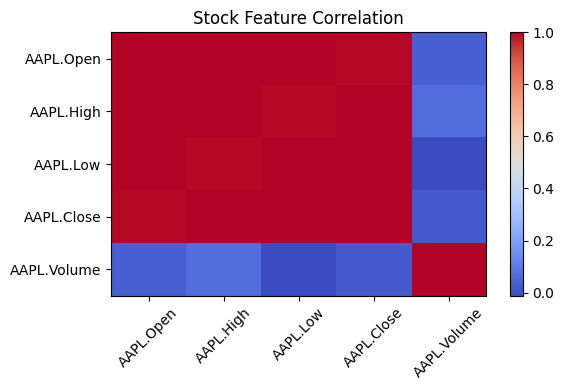

In [5]:
# Correlation analysis
corr_cols = [c for c in ["AAPL.Open","AAPL.High","AAPL.Low","AAPL.Close","AAPL.Volume"] if c in df.columns]
correlation = df[corr_cols].corr()
display(correlation)
plt.figure(figsize=(6,4))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Stock Feature Correlation")
plt.tight_layout(); plt.show()


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Training samples: 404
Testing samples: 102


,Date,Forecast,Actual
0,2016-09-22,113.625269,114.620003
1,2016-09-23,113.742705,112.709999
2,2016-09-26,113.750492,112.879997
3,2016-09-27,113.743708,113.089996
4,2016-09-28,113.732991,113.949997


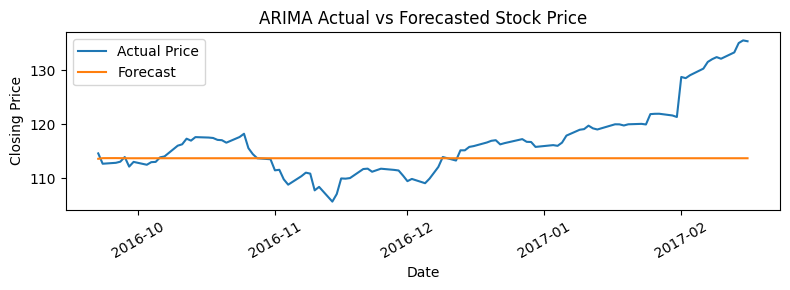

In [6]:
# ARIMA forecasting
!pip -q install statsmodels

from statsmodels.tsa.arima.model import ARIMA

stock = df[["Date","AAPL.Close"]].copy()
stock["AAPL.Close"] = pd.to_numeric(stock["AAPL.Close"], errors="coerce")
stock = stock.dropna().reset_index(drop=True)
prices = stock["AAPL.Close"]

train_size = int(len(prices) * 0.8)
train, test = prices.iloc[:train_size], prices.iloc[train_size:]
print("Training samples:", len(train))
print("Testing samples:", len(test))

model = ARIMA(train, order=(5,1,0))
model_fit = model.fit()
forecast_values = np.asarray(model_fit.forecast(steps=len(test)))

forecast = pd.DataFrame({
    "Date": stock["Date"].iloc[train_size:].values,
    "Forecast": forecast_values,
    "Actual": test.values
})
display(forecast.head())

plt.figure(figsize=(8,3))
plt.plot(forecast["Date"], forecast["Actual"], label="Actual Price")
plt.plot(forecast["Date"], forecast["Forecast"], label="Forecast")
plt.xlabel("Date"); plt.ylabel("Closing Price")
plt.title("ARIMA Actual vs Forecasted Stock Price")
plt.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

In [7]:
# Forecast next 30 periods using the complete dataset
final_model = ARIMA(prices, order=(5,1,0)).fit()
future_values = final_model.forecast(steps=30)
print("Next 30 predicted closing prices:")
display(future_values)

Next 30 predicted closing prices:


506    135.218875
507    135.114842
508    135.103734
509    135.122759
510    135.132657
511    135.137798
512    135.137066
513    135.135450
514    135.134862
515    135.134681
516    135.134814
517    135.134927
518    135.134953
519    135.134954
520    135.134941
521    135.134934
522    135.134934
523    135.134935
524    135.134936
525    135.134936
526    135.134936
527    135.134936
528    135.134936
529    135.134936
530    135.134936
531    135.134936
532    135.134936
533    135.134936
534    135.134936
535    135.134936
Name: predicted_mean, dtype: float64

In [ ]:
# ========== DMV PRACTICAL 7: APPLE STOCK & ARIMA FORECASTING ==========

# AIM: Analyze Apple stock prices, calculate moving averages,
# study trends/correlations and forecast prices using ARIMA.
# FLOW: Load -> Clean -> Trend -> Moving Average ->
#       Monthly Analysis -> Correlation -> ARIMA -> Forecast

# THEORY:
# Time Series = data recorded in chronological order.
# Forecasting = predicting future values using past data.
# Trend = overall upward/downward movement over time.
# Moving Average = average of recent values; smooths fluctuations.
# ARIMA = AutoRegressive Integrated Moving Average.
# AR = uses previous values; I = differencing to remove trends.
# MA = uses previous forecast errors.
# ARIMA(p,d,q): p = lag terms, d = differencing, q = error lags.
# ARIMA(5,1,0) = 5 AR lags, 1 difference, 0 MA lags.
# Stationarity = statistical properties remain stable over time.
# Correlation = linear relationship between variables (-1 to +1).

# LIBRARIES:
# pandas(pd) = data handling; numpy(np) = numerical calculations.
# matplotlib(plt) = plotting graphs.
# statsmodels = statistical modeling and time-series forecasting.

# DATA LOADING:
# pd.read_csv(url) = loads Apple stock CSV.
# shape = (rows, columns); columns.tolist() = column names.
# head() = first 5 rows; tail() = last 5 rows.
# info() = column types/counts; describe() = statistics.
# isnull().sum() = missing values per column.
# display() = shows formatted tables.

# DATE PREPARATION:
# pd.to_datetime(df["Date"]) = converts text to dates.
# sort_values("Date") = sorts records chronologically.
# reset_index(drop=True) = resets row numbers, removes old index.

# STOCK PRICE TREND:
# plt.figure(figsize=(8,3)) = graph size in inches.
# plt.plot(Date,Close) = line graph of closing prices over time.
# xlabel()/ylabel() = axis labels; title() = graph heading.
# xticks(rotation=30) = rotates date labels.
# tight_layout() = adjusts spacing; show() = displays graph.

# MOVING AVERAGES:
# rolling(window=20).mean() = average of last 20 observations.
# rolling(window=50).mean() = average of last 50 observations.
# MA_20 = short-term trend; MA_50 = longer-term trend.
# rolling() = moving window; mean() = calculates average.
# label="..." = line name; legend() = displays line labels.
# Initial MA values are NaN until enough observations exist.
# NOTE: 20/50 observations are trading rows, not calendar days.

# MONTHLY ANALYSIS:
# .dt.year = extracts year; .dt.month = extracts month number.
# groupby("Month")["AAPL.Close"].mean() = monthly average price.
# plot(marker="o") = line graph with circular markers.
# xticks(range(1,13)) = shows month numbers 1 to 12.
# NOTE: Groups same months across all years, not separately by year.

# TRADING VOLUME:
# AAPL.Volume = number of shares traded.
# groupby("Month")["AAPL.Volume"].mean() = average monthly volume.
# scatter(Volume,Close,alpha=0.5) = volume vs closing price.
# alpha=0.5 = 50% transparency.
# Scatter plot = shows relationship between two variables.

# CORRELATION:
# corr_cols = available stock feature columns.
# .corr() = calculates Pearson correlation matrix.
# +1 = positive; -1 = negative; 0 = no linear correlation.
# imshow(correlation,cmap="coolwarm",aspect="auto") = heatmap.
# cmap="coolwarm" = blue-red color scheme.
# aspect="auto" = automatically adjusts image proportions.
# colorbar() = color scale.
# xticks()/yticks() = sets feature labels.
# len() = counts items; range(n) = positions 0 to n-1.

# ARIMA MODEL:
# !pip -q install statsmodels = installs library quietly in notebook.
# from statsmodels.tsa.arima.model import ARIMA = imports model.
# copy() = creates independent DataFrame copy.
# pd.to_numeric(...,errors="coerce") = converts to numbers.
# errors="coerce" = invalid values become NaN.
# dropna() = removes missing rows.
# prices = closing price time series.

# TRAIN-TEST SPLIT:
# int(len(prices)*0.8) = calculates 80% training size.
# iloc[:train_size] = first 80% observations (training).
# iloc[train_size:] = remaining 20% (testing).
# Chronological split is used to preserve time order.

# MODEL TRAINING & FORECASTING:
# ARIMA(train,order=(5,1,0)) = creates ARIMA model.
# model.fit() = learns model parameters from training data.
# forecast(steps=len(test)) = predicts entire test period.
# np.asarray() = converts predictions into NumPy array.
# pd.DataFrame({...}) = table of Date, Forecast and Actual.
# .values = array values of selected data.
# Actual = real prices; Forecast = predicted prices.
# plt.plot() = compares actual and forecasted prices.

# FUTURE FORECAST:
# ARIMA(prices,order=(5,1,0)).fit() = trains on full dataset.
# forecast(steps=30) = predicts next 30 observations.
# These are future periods, not necessarily 30 calendar days.
# NOTE: Forecast is uncertain; stock prices are difficult to predict.

# ========== 4 IMPORTANT VIVA QUESTIONS ==========

# Q1. What is Time Series Analysis?
# Ans: Analyzing data recorded over time to identify
#      trends, patterns and make future predictions.

# Q2. What is ARIMA?
# Ans: AutoRegressive Integrated Moving Average,
#      a statistical model used for time-series forecasting.

# Q3. What do p, d and q mean in ARIMA?
# Ans: p = past value lags, d = differencing,
#      q = past forecast error lags.

# Q4. What is a Moving Average and why is it used?
# Ans: Average of recent observations, used to smooth
#      fluctuations and identify trends.

# FINAL VIVA EXPLANATION:
# "We load Apple stock data, convert dates and sort records.
# We visualize closing prices, calculate 20-day and 50-day
# moving averages, analyze monthly prices and trading volume,
# and study feature correlations. Then we split data 80:20,
# train ARIMA(5,1,0), compare predicted and actual prices,
# and forecast the next 30 periods using the complete dataset."